# ch02_1. 선형회귀의 순전파와 손실

## 개요

- Linear Regression(리니어 리그레션, 선형회귀)의 역할을 이해합니다.

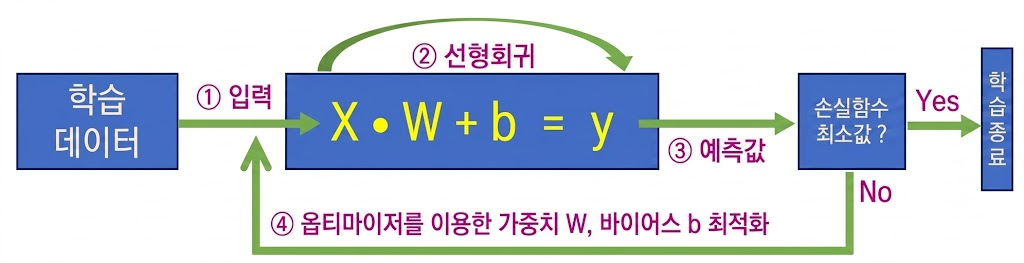

- 같은 학습 함수를 센서 보정 데이터에 재사용합니다.

## 1. 라이브러리와 학습 데이터 준비

다음 세 점을 사용합니다.

| 입   력 $ x $ | 실 제 값 $ y $ |
|---:|---:|
| 1 | 1 |
| 2 | 2 |
| 3 | 3 |

데이터의 관계는 $y=x$이므로, 가장 잘 맞는 직선은 기울기 1, 절편 0입니다.

In [ ]:
#01_데이터 준비
import torch

x_train = torch.tensor([1.0, 2.0, 3.0])
y_train = torch.tensor([1.0, 2.0, 3.0])

print("입력:", x_train)
print("실제값:", y_train)

입력: tensor([1., 2., 3.])
실제값: tensor([1., 2., 3.])


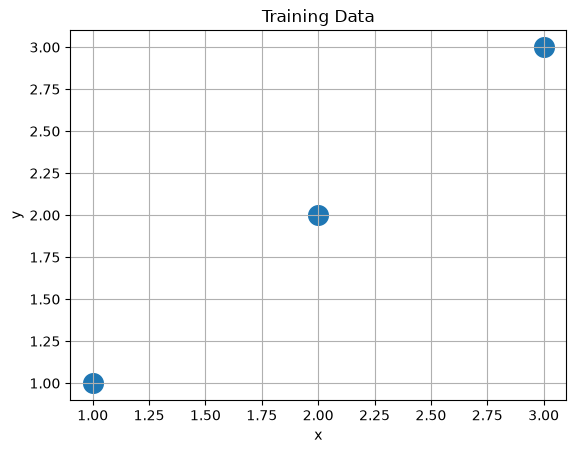

In [ ]:
# <참고> 입력 데이터와 실제값을 점으로 표시
import matplotlib.pyplot as plt

plt.scatter(x_train, y_train, s=200)  #s는 점 크기

plt.xlabel("x")
plt.ylabel("y")
plt.title("Training Data")
plt.grid(True)

#해상도300, 불필요여백 삭제
plt.savefig("./png/ch02_1_1.png", dpi=300, bbox_inches="tight") 
plt.show()

## 2. 순전파로 예측값 계산하기

선형회귀는 입력과 출력의 관계를 다음 직선으로 표현합니다.

$$
\hat{y}=Wx+b
$$

- $\hat{y}$: Prediction(프리딕션, 예측값)
- $W$: Weight(웨이트, 가중치 또는 직선의 기울기)
- $b$: Bias(바이어스, 편향 또는 직선의 절편)
- $x$: Input(인풋, 입력값)

Forward(포워드, 순전파)는 현재 $W$와 $b$를 사용하여 예측값을 계산하는 과정입니다.

In [ ]:
#02_순전파로 예측 : 가설(H)
# 예시 직선: y = 0.5x + 2

W_example = 0.5
b_example = 2.0

y_pred = W_example * x_train + b_example #예측 값

print("예측값:", y_pred)
print("실제값:", y_train)
print("오차:", y_pred - y_train)

예측값: tensor([2.5000, 3.0000, 3.5000])
실제값: tensor([1., 2., 3.])
오차: tensor([1.5000, 1.0000, 0.5000])


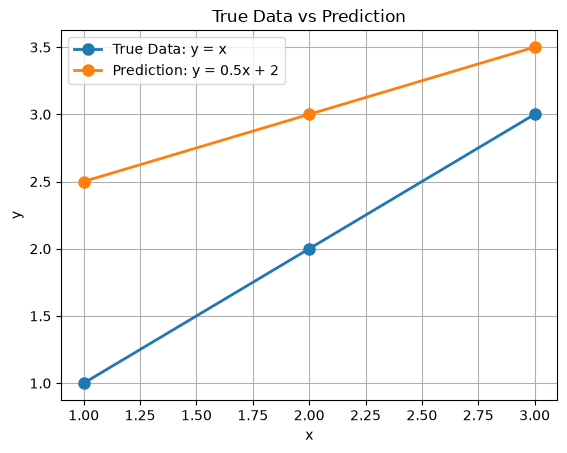

In [21]:
#<참고>
plt.plot(x_train, y_train, marker="o", markersize=8,
    linewidth=2, label="True Data: y = x")

# 예측값으로 만든 가설 직선 표시
plt.plot(x_train, y_pred, marker="o", markersize=8,
    linewidth=2, label="Prediction: y = 0.5x + 2")

plt.xlabel("x")
plt.ylabel("y")
plt.title("True Data vs Prediction")
plt.grid(True)
plt.legend()

plt.savefig("./png/ch02_1_2.png", dpi=300, bbox_inches="tight")
plt.show()

## 3. MSE로 Loss(손실) 계산하기

Loss(로스, 손실)는 예측값이 실제값과 얼마나 다른지를 나타내는 숫자입니다.

MSE(엠에스이, Mean Squared Error: 평균제곱오차)는 각 오차를 제곱한 뒤 평균을 계산합니다.

$$
\mathrm{MSE}
=
\frac{1}{m}
\sum_{i=1}^{m}
(\hat{y}_i-y_i)^2
$$

계산 순서:

1. 예측값과 실제값의 차이를 구합니다.
2. 음수와 양수가 서로 상쇄되지 않도록 제곱합니다.
3. 모든 제곱 오차의 평균을 구합니다.

Loss가 작을수록 현재 직선이 데이터에 더 잘 맞습니다.

In [7]:
#03. loss 계산
errors = y_pred - y_train
squared_errors = errors ** 2
mse = squared_errors.mean()

print("오차:", errors)
print("제곱 오차:", squared_errors)
print("MSE:", mse.item())

오차: tensor([1.5000, 1.0000, 0.5000])
제곱 오차: tensor([2.2500, 1.0000, 0.2500])
MSE: 1.1666666269302368


## 4. 두 직선의 Loss 비교하기

사람은 그래프를 보고 더 좋은 직선을 판단할 수 있지만, 컴퓨터는 Loss를 숫자로 비교합니다.

In [8]:
#04. 첫 번째 직선: y = 1x + 0
pred_1 = 1.0 * x_train + 0.0
loss_1 = ((pred_1 - y_train) ** 2).mean()

# 두 번째 직선: y = 0.5x + 2
pred_2 = 0.5 * x_train + 2.0
loss_2 = ((pred_2 - y_train) ** 2).mean()

print("y = 1.0x + 0.0의 Loss:", loss_1.item())
print("y = 0.5x + 2.0의 Loss:", round(loss_2.item(), 4))

y = 1.0x + 0.0의 Loss: 0.0
y = 0.5x + 2.0의 Loss: 1.1667


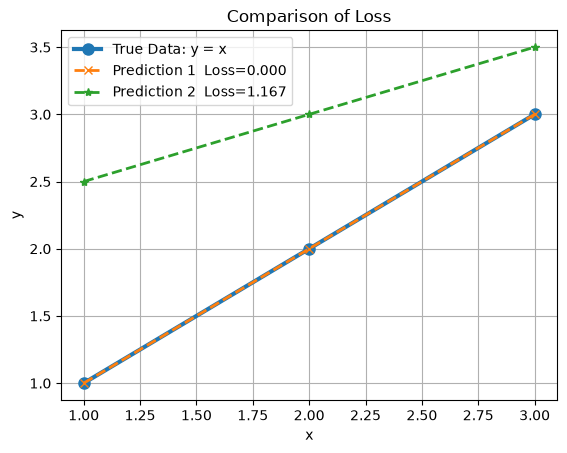

In [22]:
# <참고> 두 직선의 Loss 비교

plt.plot(x_train, y_train, marker="o", markersize=8,
         linewidth=3, label="True Data: y = x")

plt.plot(x_train, pred_1, marker="x", linestyle="--",
         linewidth=2, label=f"Prediction 1  Loss={loss_1.item():.3f}")

plt.plot(x_train, pred_2, marker="*", linestyle="--",
         linewidth=2, label=f"Prediction 2  Loss={loss_2.item():.3f}")

plt.xlabel("x")
plt.ylabel("y")
plt.title("Comparison of Loss")
plt.grid(True)
plt.legend()

plt.savefig("./png/ch02_1_3.png", dpi=300, bbox_inches="tight")
plt.show()

## 5. 선형회귀 학습 함수 만들기

학습은 다음 네 단계를 반복합니다.

| 단계 | 코드 | 의미 |
|---|---|---|
| Forward | `prediction = W * x + b` | 예측값 계산 |
| Loss | `loss = ...` | 예측 오차 계산 |
| Backward | `loss.backward()` | $W$, $b$의 기울기 계산 |
| Update | `optimizer.step()` | $W$, $b$ 갱신 |

SGD(Stochastic Gradient Descent, 확률적 경사하강법)는 기울기의 반대 방향으로 매개변수를 조금씩 이동합니다.

$$
\text{새 매개변수}
=
\text{현재 매개변수}
-
\text{학습률}
\times
\text{기울기}
$$

아래 함수는 같은 학습 코드를 여러 데이터에 재사용하기 위한 간단한 함수입니다.

In [10]:
#05.선형회귀 함수
def train_line(x, y, learning_rate=0.01, epochs=2000):
    # 학습할 가중치와 편향
    W = torch.tensor(0.0, requires_grad=True)
    b = torch.tensor(0.0, requires_grad=True)

    optimizer = torch.optim.SGD([W, b], lr=learning_rate)

    first_loss = None

    for epoch in range(epochs):
        optimizer.zero_grad()

        # 1. 순전파
        prediction = W * x + b

        # 2. 손실 계산
        loss = ((prediction - y) ** 2).mean()
        print(epoch, loss)

        # 첫 번째 Loss 저장
        if epoch == 0:
            first_loss = loss.item()

        # 3. 역전파
        loss.backward()

        # 4. 매개변수 갱신
        optimizer.step()

    # return : W, b, first_loss, loss
    return W.detach(), b.detach(), first_loss, loss.item()

## 6. 기본 데이터 학습하기

학습이 잘 진행되면 다음과 같이 변합니다.

- $W$는 1에 가까워집니다.
- $b$는 0에 가까워집니다.
- Loss는 처음보다 매우 작아집니다.

In [11]:
#06.기본데이터 학습
W, b, first_loss, final_loss = train_line(x_train, y_train)

print("학습된 W:", W.item())
print("학습된 b:", b.item())
print("Loss 변화:", first_loss, "→", final_loss)

0 tensor(4.6667, grad_fn=<MeanBackward0>)
1 tensor(3.6927, grad_fn=<MeanBackward0>)
2 tensor(2.9229, grad_fn=<MeanBackward0>)
3 tensor(2.3143, grad_fn=<MeanBackward0>)
4 tensor(1.8333, grad_fn=<MeanBackward0>)
5 tensor(1.4530, grad_fn=<MeanBackward0>)
6 tensor(1.1524, grad_fn=<MeanBackward0>)
7 tensor(0.9148, grad_fn=<MeanBackward0>)
8 tensor(0.7270, grad_fn=<MeanBackward0>)
9 tensor(0.5785, grad_fn=<MeanBackward0>)
10 tensor(0.4611, grad_fn=<MeanBackward0>)
11 tensor(0.3683, grad_fn=<MeanBackward0>)
12 tensor(0.2949, grad_fn=<MeanBackward0>)
13 tensor(0.2368, grad_fn=<MeanBackward0>)
14 tensor(0.1910, grad_fn=<MeanBackward0>)
15 tensor(0.1547, grad_fn=<MeanBackward0>)
16 tensor(0.1260, grad_fn=<MeanBackward0>)
17 tensor(0.1033, grad_fn=<MeanBackward0>)
18 tensor(0.0853, grad_fn=<MeanBackward0>)
19 tensor(0.0711, grad_fn=<MeanBackward0>)
20 tensor(0.0598, grad_fn=<MeanBackward0>)
21 tensor(0.0509, grad_fn=<MeanBackward0>)
22 tensor(0.0439, grad_fn=<MeanBackward0>)
23 tensor(0.0383, gra

## 7. 새로운 입력값 예측하기

학습이 끝난 뒤에는 학습된 직선에 새로운 입력값을 넣어 결과를 예측합니다.

예측할 때는 기울기를 계산할 필요가 없으므로 `torch.no_grad()`를 사용합니다.

In [13]:
#07. 새로운 입력값 예측
x_new = torch.tensor([2.5, 5.0])

with torch.no_grad():
    y_new = W * x_new + b

print("새 입력:", x_new)
print("예측값:", y_new)

새 입력: tensor([2.5000, 5.0000])
예측값: tensor([2.4997, 4.9964])


##8. 실무 예제: 센서 입력 전압 보정

센서의 입력 전압과 실제 측정값 사이의 관계를 학습합니다.

| 입력 전압 | 실제 측정값 |
|---:|---:|
| 0.5 V | 11 |
| 1.0 V | 21 |
| 1.5 V | 31 |
| 2.0 V | 41 |

이 데이터는 대략 다음 관계를 가집니다.

$$
y=20x+1
$$

앞에서 만든 `train_line()` 함수를 그대로 재사용합니다.

In [14]:
#08. 예제-센서입력 전압 보정
voltage_data = torch.tensor([0.5, 1.0, 1.5, 2.0])
measured_data = torch.tensor([11.0, 21.0, 31.0, 41.0])

# 생성한 선형회귀학습 함수 train_line 사용
sensor_W, sensor_b, sensor_first_loss, sensor_final_loss = train_line(
    voltage_data, measured_data, learning_rate=0.05, epochs=3000,)

new_voltage = torch.tensor(1.25)

with torch.no_grad():
    corrected_value = sensor_W * new_voltage + sensor_b

print("학습된 W:", sensor_W.item())
print("학습된 b:", sensor_b.item())

print("Loss 변화:", sensor_first_loss, "→", sensor_final_loss)
print("1.25 V 예측값:", corrected_value.item())

0 tensor(801., grad_fn=<MeanBackward0>)
1 tensor(425.5893, grad_fn=<MeanBackward0>)
2 tensor(228.7750, grad_fn=<MeanBackward0>)
3 tensor(125.5318, grad_fn=<MeanBackward0>)
4 tensor(71.3142, grad_fn=<MeanBackward0>)
5 tensor(42.7843, grad_fn=<MeanBackward0>)
6 tensor(27.7153, grad_fn=<MeanBackward0>)
7 tensor(19.7012, grad_fn=<MeanBackward0>)
8 tensor(15.3860, grad_fn=<MeanBackward0>)
9 tensor(13.0113, grad_fn=<MeanBackward0>)
10 tensor(11.6557, grad_fn=<MeanBackward0>)
11 tensor(10.8367, grad_fn=<MeanBackward0>)
12 tensor(10.3011, grad_fn=<MeanBackward0>)
13 tensor(9.9165, grad_fn=<MeanBackward0>)
14 tensor(9.6133, grad_fn=<MeanBackward0>)
15 tensor(9.3550, grad_fn=<MeanBackward0>)
16 tensor(9.1226, grad_fn=<MeanBackward0>)
17 tensor(8.9058, grad_fn=<MeanBackward0>)
18 tensor(8.6993, grad_fn=<MeanBackward0>)
19 tensor(8.5004, grad_fn=<MeanBackward0>)
20 tensor(8.3075, grad_fn=<MeanBackward0>)
21 tensor(8.1197, grad_fn=<MeanBackward0>)
22 tensor(7.9365, grad_fn=<MeanBackward0>)
23 tenso

## 10. 핵심 정리

- 선형회귀는 $\hat{y}=Wx+b$ 형태의 직선을 학습합니다.
- `backward()`는 Loss를 줄이기 위한 기울기를 계산합니다.
- 학습된 모델은 새로운 입력값을 예측하는 데 사용합니다.